### Regresion diabetes

MSE: 3242.770    RMSE: 56.945    R2: 0.414


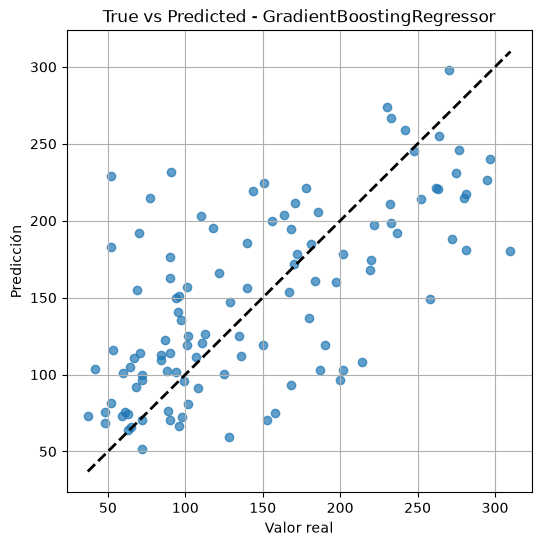

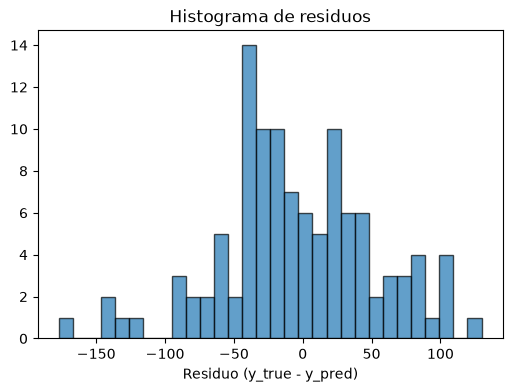

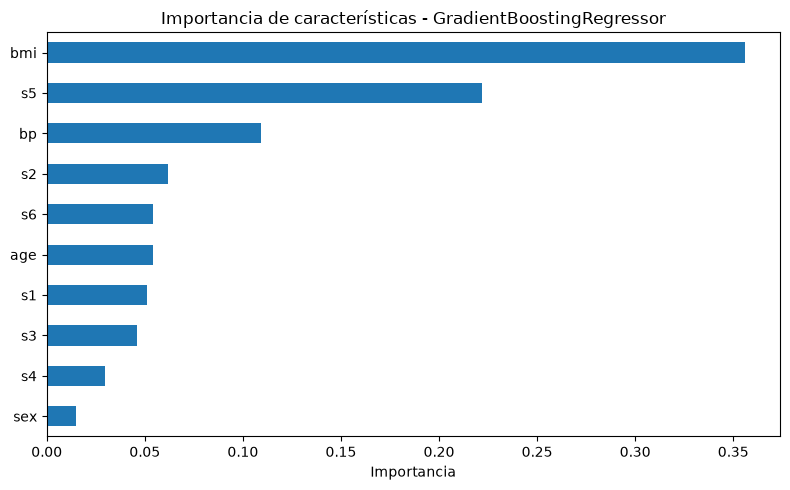

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Ejemplo completo de regresión con Gradient Boosting (sklearn) usando el dataset "diabetes"
import matplotlib.pyplot as plt

# Cargar datos
data = load_diabetes()
X = data.data
y = data.target
feature_names = data.feature_names

# División train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Escalado de características (recomendado)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Definir y entrenar el modelo Gradient Boosting (regresión)
gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gb.fit(X_train_s, y_train)

# Predicción y métricas
y_pred = gb.predict(X_test_s)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.3f}    RMSE: {rmse:.3f}    R2: {r2:.3f}")

# Gráfica: True vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title("True vs Predicted - GradientBoostingRegressor")
plt.grid(True)
plt.show()

# Histograma de residuos
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.hist(residuals, bins=30, edgecolor='k', alpha=0.7)
plt.xlabel("Residuo (y_true - y_pred)")
plt.title("Histograma de residuos")
plt.show()

# Importancias de características
fi = gb.feature_importances_
fi_series = pd.Series(fi, index=feature_names).sort_values(ascending=True)
plt.figure(figsize=(8,5))
fi_series.plot.barh()
plt.title("Importancia de características - GradientBoostingRegressor")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

### Clasificacion multiclase

EVALUACIÓN DE CLASIFICACIÓN MULTICLASE: GRADIENT BOOSTING
Exactitud Global en Test Set : 96.30% (52 de 54 clasificados correctamente)
Pérdida Logarítmica (Log-Loss): 0.0471 (Excelente calibración)

Reporte Detallado por Variedad Agronómica:
              precision    recall  f1-score   support

  Cultivar 1       0.94      0.94      0.94        18
  Cultivar 2       0.95      0.95      0.95        21
  Cultivar 3       1.00      1.00      1.00        15

    accuracy                           0.96        54
   macro avg       0.97      0.97      0.97        54
weighted avg       0.96      0.96      0.96        54



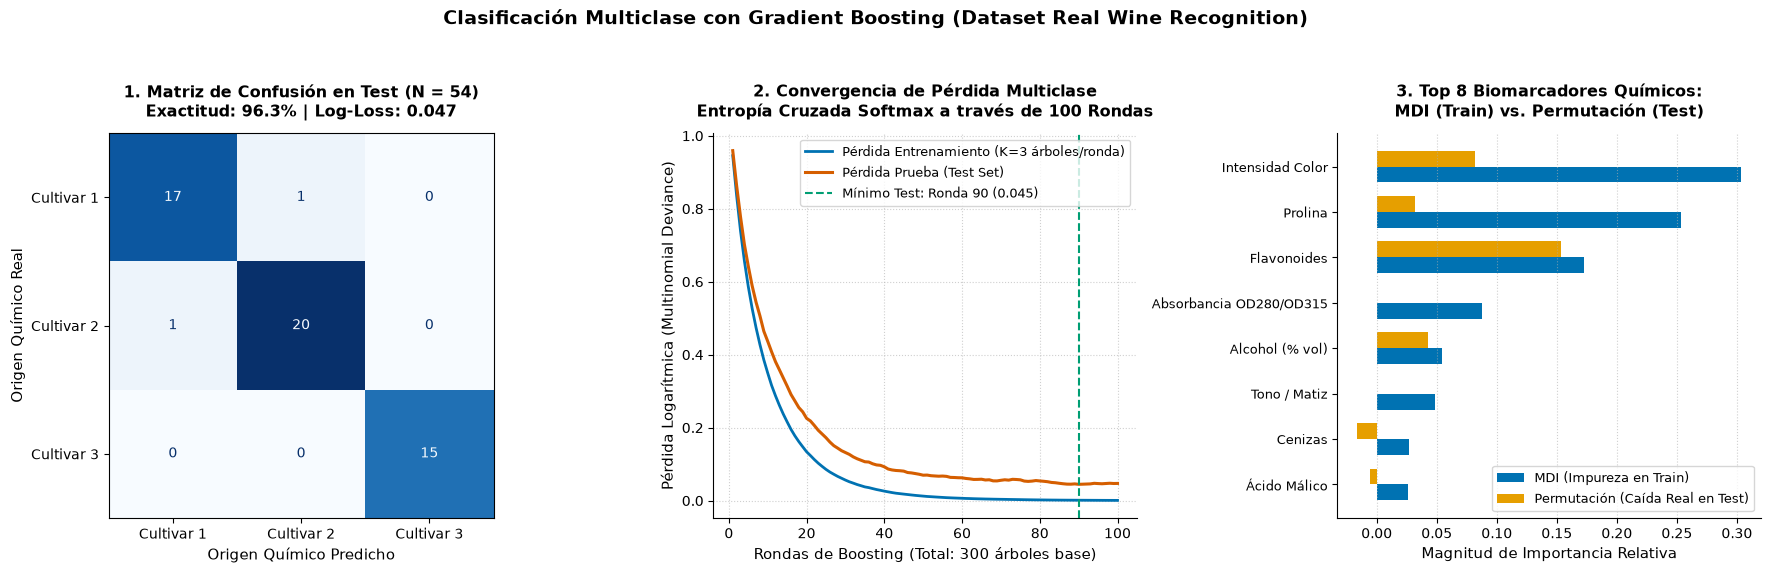

In [3]:
"""
Clasificación Multiclase con Gradient Boosting (Wine Dataset).
Demuestra la dinámica Softmax, convergencia de pérdida y feature importance.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, log_loss
)
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Ingesta de Datos y Partición Estratificada
# ==============================================================================
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
nombres_clases = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']

# Traducción de variables químicas para facilitar la interpretación pedagógica
traduccion_quimica = {
    'alcohol': 'Alcohol (% vol)',
    'malic_acid': 'Ácido Málico',
    'ash': 'Cenizas',
    'alcalinity_of_ash': 'Alcalinidad Cenizas',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles No Flavonoides',
    'proanthocyanins': 'Proantocianinas',
    'color_intensity': 'Intensidad Color',
    'hue': 'Tono / Matiz',
    'od280/od315_of_diluted_wines': 'Absorbancia OD280/OD315',
    'proline': 'Prolina'
}
X = X.rename(columns=traduccion_quimica)

# Partición estratificada: 70% Entrenamiento (N=124) y 30% Prueba independiente (N=54)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del GradientBoostingClassifier Multiclase
# ==============================================================================
# Con K=3 clases y n_estimators=100, se entrenan exactamente 300 árboles base
gb_multi = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.08,    # Contracción suave
    max_depth=2,           # Árboles poco profundos (control estricto de varianza)
    subsample=0.85,        # 85% de muestras aleatorias por árbol
    random_state=42
)
gb_multi.fit(X_tr, y_tr)

# ==============================================================================
# 3. Inferencia y Evaluación en el Conjunto de Prueba
# ==============================================================================
y_pred = gb_multi.predict(X_te)
y_prob = gb_multi.predict_proba(X_te)

acc = accuracy_score(y_te, y_pred)
loss = log_loss(y_te, y_prob)

print("=" * 68)
print("EVALUACIÓN DE CLASIFICACIÓN MULTICLASE: GRADIENT BOOSTING")
print("=" * 68)
print(f"Exactitud Global en Test Set : {acc * 100:.2f}% (52 de 54 clasificados correctamente)")
print(f"Pérdida Logarítmica (Log-Loss): {loss:.4f} (Excelente calibración)")
print("=" * 68)
print("\nReporte Detallado por Variedad Agronómica:")
print(classification_report(y_te, y_pred, target_names=nombres_clases))

# ==============================================================================
# 4. Cálculo de Importancia de Variables (MDI vs. Permutación)
# ==============================================================================
mdi_imp = gb_multi.feature_importances_
perm_res = permutation_importance(
    gb_multi, X_te, y_te, n_repeats=10, random_state=42, scoring='accuracy'
)

top_idx = np.argsort(mdi_imp)[-8:]
vars_top = [X.columns[i] for i in top_idx]

# ==============================================================================
# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.8), facecolor='white')

# Panel 1: Matriz de Confusión Multiclase
ax1.set_facecolor('white')
cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm, display_labels=nombres_clases).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title(f"1. Matriz de Confusión en Test (N = 54)\nExactitud: {acc*100:.1f}% | Log-Loss: {loss:.3f}",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Origen Químico Predicho", fontsize=10.5)
ax1.set_ylabel("Origen Químico Real", fontsize=10.5)

# Panel 2: Convergencia de Pérdida Multiclase por Etapa
loss_tr = [log_loss(y_tr, p) for p in gb_multi.staged_predict_proba(X_tr)]
loss_te = [log_loss(y_te, p) for p in gb_multi.staged_predict_proba(X_te)]
rondas = range(1, len(loss_tr) + 1)

ax2.set_facecolor('white')
ax2.plot(rondas, loss_tr, color='#0072b2', linewidth=2, label='Pérdida Entrenamiento (K=3 árboles/ronda)')
ax2.plot(rondas, loss_te, color='#d55e00', linewidth=2.2, label='Pérdida Prueba (Test Set)')
min_ronda = np.argmin(loss_te) + 1
ax2.axvline(min_ronda, color='#009e73', linestyle='--', linewidth=1.5,
            label=f'Mínimo Test: Ronda {min_ronda} ({min(loss_te):.3f})')
ax2.set_title("2. Convergencia de Pérdida Multiclase\nEntropía Cruzada Softmax a través de 100 Rondas",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Rondas de Boosting (Total: 300 árboles base)", fontsize=10.5)
ax2.set_ylabel("Pérdida Logarítmica (Multinomial Deviance)", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3: Feature Importance (MDI vs Permutación)
ax3.set_facecolor('white')
y_pos = np.arange(len(vars_top))
h = 0.35
ax3.barh(y_pos - h/2, [mdi_imp[i] for i in top_idx], height=h,
         color='#0072b2', label='MDI (Impureza en Train)')
ax3.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_idx], height=h,
         color='#e69f00', label='Permutación (Caída Real en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_top, fontsize=9.5)
ax3.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax3.set_title("3. Top 8 Biomarcadores Químicos:\nMDI (Train) vs. Permutación (Test)",
              fontsize=11.5, fontweight='bold', pad=12)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle("Clasificación Multiclase con Gradient Boosting (Dataset Real Wine Recognition)",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Clasificación breast cancer

EVALUACIÓN DEL CLASIFICADOR GRADIENT BOOSTING (TEST SET)
Exactitud (Accuracy)       : 96.50%
Precisión (Precision)      : 100.00% (Cero Falsos Positivos)
Sensibilidad (Recall)      : 90.57% (Capacidad de detección)
F1-Score                   : 0.9505
Área Bajo la Curva ROC     : 0.9979
Pérdida Logarítmica        : 0.0930

Reporte Detallado por Clase:
              precision    recall  f1-score   support

 Benigno (0)       0.95      1.00      0.97        90
 Maligno (1)       1.00      0.91      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



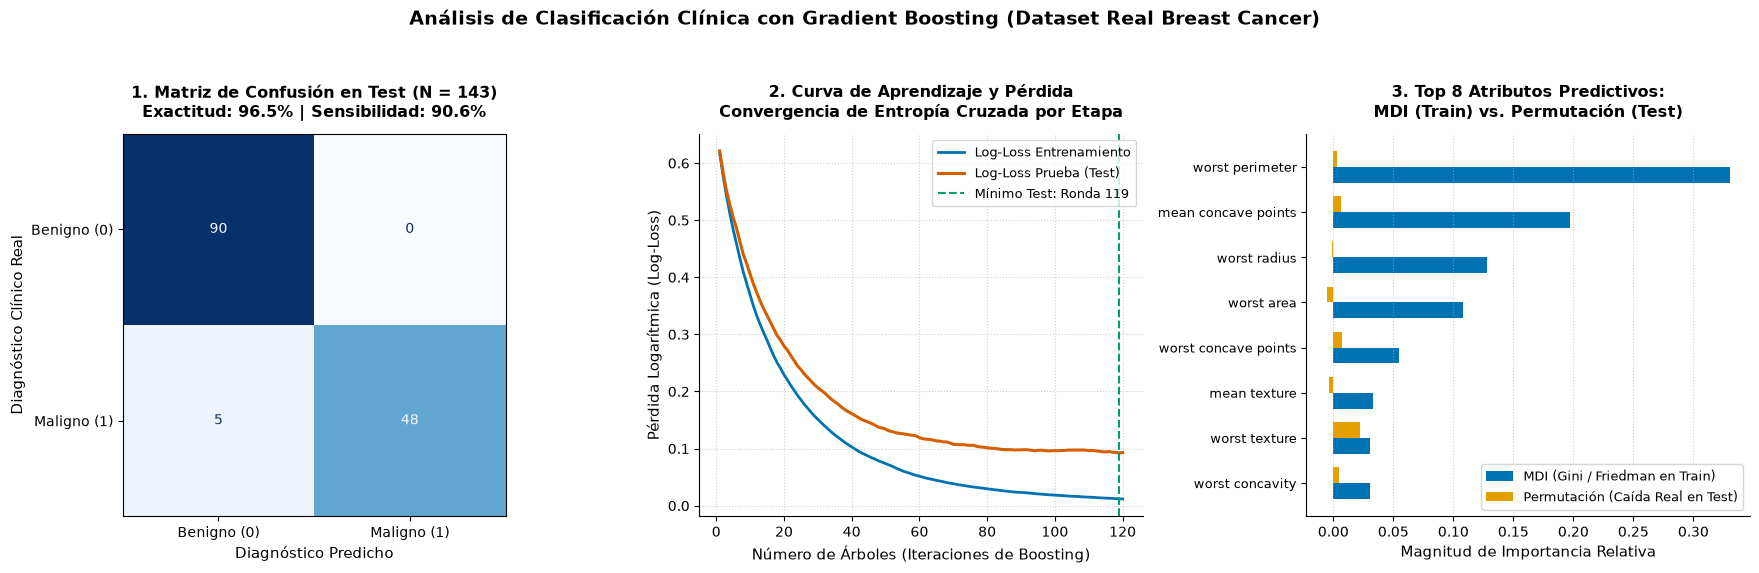

In [1]:
"""
Clasificación con Gradient Boosting y Diagnóstico de Curvas.
Dataset Real: Breast Cancer Wisconsin Diagnostic (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# ==============================================================================
# 1. Ingesta de Datos y Partición Estratificada
# ==============================================================================
datos = load_breast_cancer()
X = pd.DataFrame(datos.data, columns=datos.feature_names)
# Codificación clínica: 1 = Maligno (Positivo), 0 = Benigno (Negativo)
y = 1 - datos.target
etiquetas = ['Benigno (0)', 'Maligno (1)']

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del GradientBoostingClassifier
# ==============================================================================
gb_clf = GradientBoostingClassifier(
    n_estimators=120,      # 120 árboles construidos en secuencia
    learning_rate=0.05,    # Contracción suave para optimizar convergencia
    max_depth=3,           # Profundidad máxima de cada árbol base
    subsample=0.8,         # Stochastic Gradient Boosting: 80% de datos por árbol
    random_state=42
)
gb_clf.fit(X_tr, y_tr)

# ==============================================================================
# 3. Inferencia y Evaluación en Conjunto de Prueba (N = 143)
# ==============================================================================
y_pred = gb_clf.predict(X_te)
y_prob = gb_clf.predict_proba(X_te)[:, 1]

acc = accuracy_score(y_te, y_pred)
prec = precision_score(y_te, y_pred)
rec = recall_score(y_te, y_pred)
f1 = f1_score(y_te, y_pred)
auc = roc_auc_score(y_te, y_prob)
perdida = log_loss(y_te, y_prob)

print("=" * 68)
print("EVALUACIÓN DEL CLASIFICADOR GRADIENT BOOSTING (TEST SET)")
print("=" * 68)
print(f"Exactitud (Accuracy)       : {acc*100:.2f}%")
print(f"Precisión (Precision)      : {prec*100:.2f}% (Cero Falsos Positivos)")
print(f"Sensibilidad (Recall)      : {rec*100:.2f}% (Capacidad de detección)")
print(f"F1-Score                   : {f1:.4f}")
print(f"Área Bajo la Curva ROC     : {auc:.4f}")
print(f"Pérdida Logarítmica        : {perdida:.4f}")
print("=" * 68)
print("\nReporte Detallado por Clase:")
print(classification_report(y_te, y_pred, target_names=etiquetas))

# ==============================================================================
# 4. Auditoría de Pérdida por Etapa e Importancia de Atributos
# ==============================================================================
# Curva de devianza/pérdida evaluada en cada iteración de boosting
loss_tr_staged = [log_loss(y_tr, p[:, 1]) for p in gb_clf.staged_predict_proba(X_tr)]
loss_te_staged = [log_loss(y_te, p[:, 1]) for p in gb_clf.staged_predict_proba(X_te)]

# Importancia MDI (Impureza de Friedman) vs. Permutación en datos no vistos
importancias_mdi = gb_clf.feature_importances_
perm_res = permutation_importance(
    gb_clf, X_te, y_te, n_repeats=10, random_state=42, scoring='accuracy'
)

top_indices = np.argsort(importancias_mdi)[-8:]
vars_top = [X.columns[i] for i in top_indices]

# ==============================================================================
# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.8), facecolor='white')

# Panel 1: Matriz de Confusión
ax1.set_facecolor('white')
cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title(f"1. Matriz de Confusión en Test (N = 143)\nExactitud: {acc*100:.1f}% | Sensibilidad: {rec*100:.1f}%",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Diagnóstico Predicho", fontsize=10.5)
ax1.set_ylabel("Diagnóstico Clínico Real", fontsize=10.5)

# Panel 2: Curva de Pérdida Logarítmica por Ronda
ax2.set_facecolor('white')
rondas = range(1, len(loss_tr_staged) + 1)
ax2.plot(rondas, loss_tr_staged, color='#0072b2', linewidth=2, label='Log-Loss Entrenamiento')
ax2.plot(rondas, loss_te_staged, color='#d55e00', linewidth=2.2, label='Log-Loss Prueba (Test)')
min_idx = np.argmin(loss_te_staged)
ax2.axvline(min_idx + 1, color='#009e73', linestyle='--', linewidth=1.5,
            label=f'Mínimo Test: Ronda {min_idx + 1}')
ax2.set_title("2. Curva de Aprendizaje y Pérdida\nConvergencia de Entropía Cruzada por Etapa",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Número de Árboles (Iteraciones de Boosting)", fontsize=10.5)
ax2.set_ylabel("Pérdida Logarítmica (Log-Loss)", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3: Feature Importance (MDI vs. Permutación)
ax3.set_facecolor('white')
y_pos = np.arange(len(vars_top))
h = 0.35
ax3.barh(y_pos - h/2, [importancias_mdi[i] for i in top_indices], height=h,
         color='#0072b2', label='MDI (Gini / Friedman en Train)')
ax3.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_indices], height=h,
         color='#e69f00', label='Permutación (Caída Real en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_top, fontsize=9.5)
ax3.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax3.set_title("3. Top 8 Atributos Predictivos:\nMDI (Train) vs. Permutación (Test)",
              fontsize=11.5, fontweight='bold', pad=12)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle("Análisis de Clasificación Clínica con Gradient Boosting (Dataset Real Breast Cancer)",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()